In [ ]:
!pip install -q kaggle

In [ ]:
from google.colab import files
print("Faça o upload do seu arquivo kaggle.json:")
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d groffo/ads16-dataset
!unzip -q ads16-dataset.zip -d /content/ads16_dataset
print("Download e extração concluídos!")

Faça o upload do seu arquivo kaggle.json:


cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/groffo/ads16-dataset
License(s): other
100% 1.47G/1.47G [00:19<00:00, 79.2MB/s]

Download e extração concluídos!


In [ ]:
import os
import gc
import torch
import random
import matplotlib.pyplot as plt
from PIL import Image
from transformers import CLIPProcessor, CLIPModel
from tqdm import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Executando no dispositivo: {device}")

# Função para mapear todos os arquivos de imagem do dataset
def get_image_paths(root_dir):
    image_paths = []
    for dirpath, _, filenames in os.walk(root_dir):
        for f in filenames:
            if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                image_paths.append(os.path.join(dirpath, f))
    return image_paths

# O diretório agora reflete o caminho onde descompactamos o zip do Kaggle
ADS16_DIR = "/content/ads16_dataset"
todas_imagens = get_image_paths(ADS16_DIR)

print(f"Total de imagens encontradas no dataset: {len(todas_imagens)}")

# Amostragem para evitar estouro de RAM (limitado a 500 imagens)
TAMANHO_SUBSET = min(500, len(todas_imagens))

if todas_imagens:
    random.seed(12)
    subset_caminhos = random.sample(todas_imagens, TAMANHO_SUBSET)
else:
    subset_caminhos = []
    print("Atenção: Nenhuma imagem encontrada. Verifique a extração do Kaggle.")

if subset_caminhos:
    model_id = "openai/clip-vit-base-patch32"
    model = CLIPModel.from_pretrained(model_id).to(device)
    processor = CLIPProcessor.from_pretrained(model_id)

    TAMANHO_LOTE = 32
    embeddings_lista = []
    caminhos_processados = []

    print(f"\nIniciando a extração de embeddings de imagens")

    with torch.no_grad():
        for i in tqdm(range(0, len(subset_caminhos), TAMANHO_LOTE)):
            lote_caminhos = subset_caminhos[i : i + TAMANHO_LOTE]
            lote_imagens = []

            for caminho in lote_caminhos:
                try:
                    img = Image.open(caminho).convert("RGB")
                    lote_imagens.append(img)
                    caminhos_processados.append(caminho)
                except Exception as e:
                    pass

            if not lote_imagens:
                continue

            inputs = processor(images=lote_imagens, return_tensors="pt").to(device)

            # Passa pela rede ViT pura
            vision_outputs = model.vision_model(pixel_values=inputs["pixel_values"])
            # Pega o tensor agrupado (índice 1 da saída) e aplica a projeção de 512 dimensões
            features_lote = model.visual_projection(vision_outputs[1])

            # Normalização (L2) para similaridade de cosseno
            features_lote = features_lote / features_lote.norm(dim=-1, keepdim=True)
            embeddings_lista.append(features_lote.cpu())

            del inputs, vision_outputs, features_lote, lote_imagens
            gc.collect()
            if device == "cuda":
                torch.cuda.empty_cache()

    matriz_embeddings_imagens = torch.cat(embeddings_lista, dim=0)
    print(f"\nMatriz de Imagens concluída: {matriz_embeddings_imagens.shape}")

Executando no dispositivo: cpu
Total de imagens encontradas no dataset: 2697


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]


Iniciando a extração de embeddings de imagens




  0%|          | 0/16 [00:00<?, ?it/s]

  6%|▋         | 1/16 [00:07<01:51,  7.41s/it]

 12%|█▎        | 2/16 [00:14<01:39,  7.08s/it]

 19%|█▉        | 3/16 [00:20<01:25,  6.60s/it]

 25%|██▌       | 4/16 [00:27<01:21,  6.82s/it]

 31%|███▏      | 5/16 [00:33<01:11,  6.48s/it]

 38%|███▊      | 6/16 [00:40<01:06,  6.68s/it]

 44%|████▍     | 7/16 [00:46<00:57,  6.43s/it]

 50%|█████     | 8/16 [00:53<00:54,  6.78s/it]

 56%|█████▋    | 9/16 [00:59<00:45,  6.54s/it]

 62%|██████▎   | 10/16 [01:07<00:40,  6.76s/it]

 69%|██████▉   | 11/16 [01:13<00:32,  6.54s/it]

 75%|███████▌  | 12/16 [01:20<00:27,  6.76s/it]

 81%|████████▏ | 13/16 [01:26<00:19,  6.55s/it]

 88%|████████▊ | 14/16 [01:33<00:13,  6.74s/it]

 94%|█████████▍| 15/16 [01:42<00:07,  7.44s/it]

100%|██████████| 16/16 [01:47<00:00,  6.69s/it]


Matriz de Imagens concluída: torch.Size([500, 512])



Iniciando Cálculo de Similaridade Semântica...

--- RANKING DOS OBJETOS (Threshold = 0.24) ---
1º food product | Ocorr. na amostra: 41 | Score Médio Geral: 0.1982
2º an animal | Ocorr. na amostra: 36 | Score Médio Geral: 0.2014
3º outdoor scenery | Ocorr. na amostra: 14 | Score Médio Geral: 0.1825
4º sports equipment | Ocorr. na amostra: 12 | Score Médio Geral: 0.1977
5º cosmetics | Ocorr. na amostra: 10 | Score Médio Geral: 0.1885
6º text and typography | Ocorr. na amostra: 9 | Score Médio Geral: 0.1958
7º a toy | Ocorr. na amostra: 7 | Score Médio Geral: 0.2015
8º a person | Ocorr. na amostra: 6 | Score Médio Geral: 0.1962
9º a smartphone | Ocorr. na amostra: 6 | Score Médio Geral: 0.1894
10º jewelry | Ocorr. na amostra: 5 | Score Médio Geral: 0.1839
11º a car | Ocorr. na amostra: 3 | Score Médio Geral: 0.1861
12º clothing and apparel | Ocorr. na amostra: 3 | Score Médio Geral: 0.1928
13º a laptop | Ocorr. na amostra: 3 | Score Médio Geral: 0.1867
14º a building | Ocorr. na amostra:

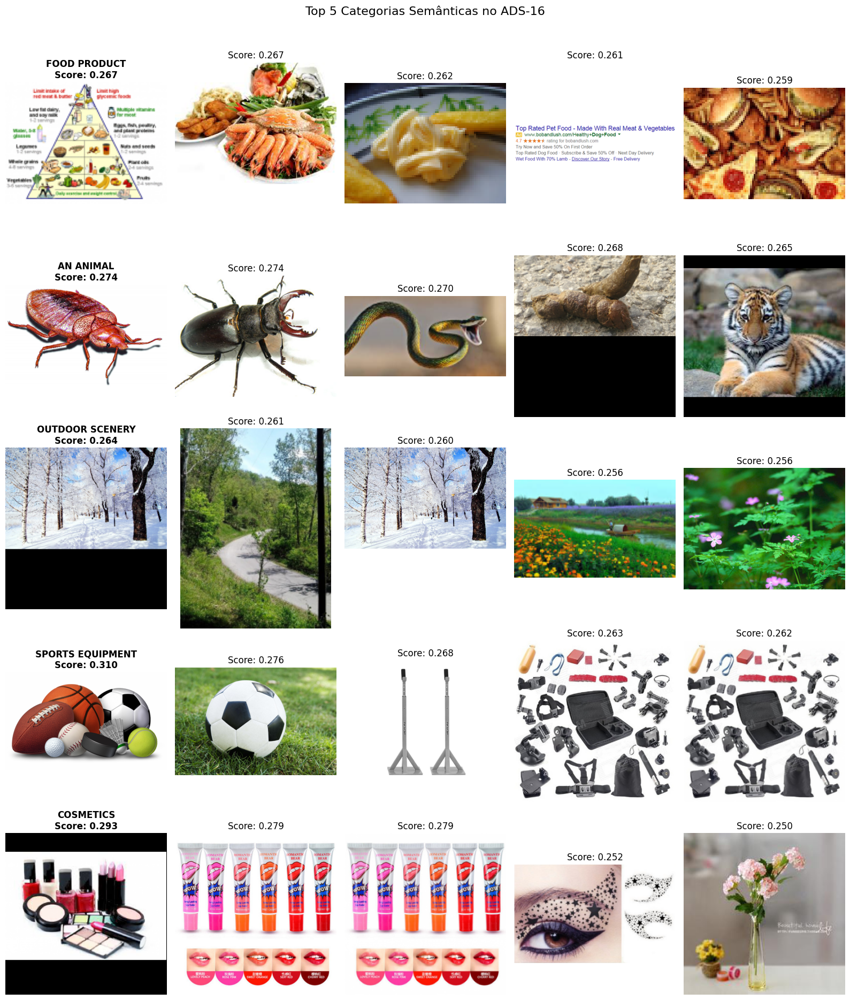

In [ ]:
print("\nIniciando Cálculo de Similaridade Semântica...")

categorias_texto = [
    "a car", "a person", "food product", "outdoor scenery", "text and typography",
    "a smartphone", "a bottle", "cosmetics", "clothing and apparel", "a laptop",
    "shoes", "a watch", "furniture", "a building", "an animal",
    "kitchen appliances", "sports equipment", "jewelry", "a beverage", "a toy"
]

inputs_texto = processor(text=categorias_texto, return_tensors="pt", padding=True).to(device)

with torch.no_grad():
    text_outputs = model.text_model(input_ids=inputs_texto["input_ids"], attention_mask=inputs_texto["attention_mask"])
    text_embeds = model.text_projection(text_outputs[1])
    text_embeds = text_embeds / text_embeds.norm(dim=-1, keepdim=True)
    text_embeds = text_embeds.cpu()

similaridade = torch.matmul(matriz_embeddings_imagens, text_embeds.T)
THRESHOLD = 0.24

ocorrencias = (similaridade > THRESHOLD).sum(dim=0).numpy()
scores_medios = similaridade.mean(dim=0).numpy()

ranking = []
for i, categoria in enumerate(categorias_texto):
    ranking.append({
        "categoria": categoria,
        "ocorrencias": ocorrencias[i],
        "score_medio": scores_medios[i]
    })

ranking_ordenado = sorted(ranking, key=lambda x: x["ocorrencias"], reverse=True)

print(f"\n--- RANKING DOS OBJETOS (Threshold = {THRESHOLD}) ---")
for i, item in enumerate(ranking_ordenado):
    print(f"{i+1}º {item['categoria']} | Ocorr. na amostra: {item['ocorrencias']} | Score Médio Geral: {item['score_medio']:.4f}")

top_5 = ranking_ordenado[:5]
fig, axes = plt.subplots(5, 5, figsize=(16, 20))
fig.suptitle(f"Top 5 Categorias Semânticas no ADS-16", fontsize=16)

for i, item in enumerate(top_5):
    cat_idx = categorias_texto.index(item["categoria"])
    scores_categoria = similaridade[:, cat_idx]
    top_img_indices = torch.topk(scores_categoria, 5).indices.numpy()

    for j, img_idx in enumerate(top_img_indices):
        ax = axes[i, j]
        img_path = caminhos_processados[img_idx]
        img = Image.open(img_path).convert("RGB")
        ax.imshow(img)
        ax.axis("off")

        if j == 0:
            ax.set_title(f"{item['categoria'].upper()}\nScore: {scores_categoria[img_idx]:.3f}", fontweight='bold')
        else:
            ax.set_title(f"Score: {scores_categoria[img_idx]:.3f}")

plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.show()


Motor de Busca Semântica...


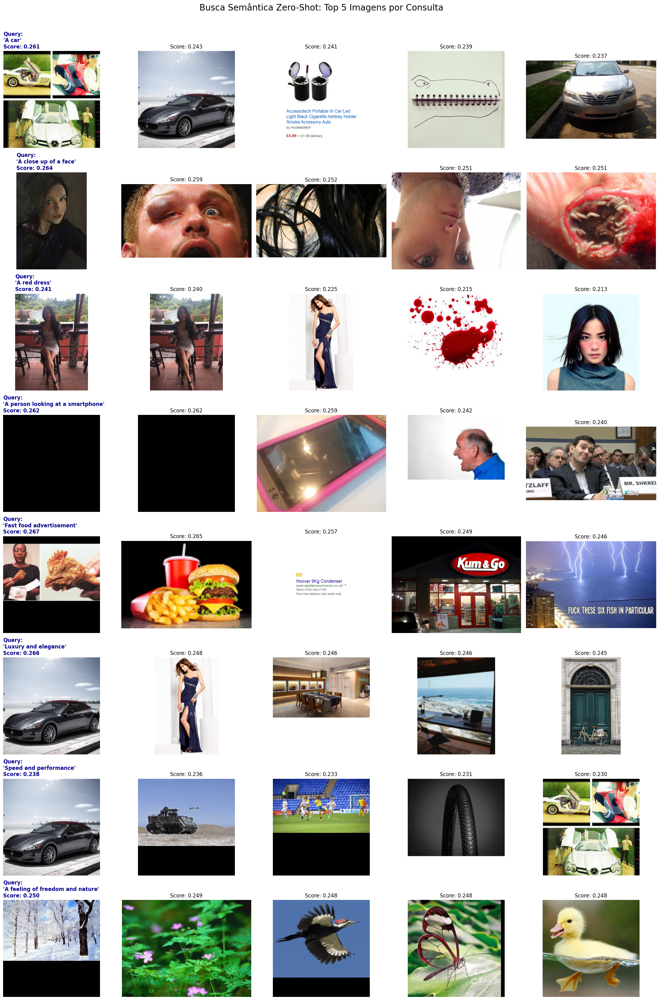

In [ ]:
print("\nMotor de Busca Semântica...")

consultas = [
    "A car",
    "A close up of a face",
    "A red dress",
    "A person looking at a smartphone",
    "Fast food advertisement",
    "Luxury and elegance",
    "Speed and performance",
    "A feeling of freedom and nature"
]

# Função de busca vetorizada
def buscar_imagens(query, top_k=5):
    # Gera embedding do texto utilizando os módulos internos para evitar erros
    inputs_texto = processor(text=[query], return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        text_outputs = model.text_model(
            input_ids=inputs_texto["input_ids"],
            attention_mask=inputs_texto["attention_mask"]
        )
        text_embeds = model.text_projection(text_outputs[1])
        text_embeds = text_embeds / text_embeds.norm(dim=-1, keepdim=True)
        text_embeds = text_embeds.cpu()

    similaridade = torch.matmul(matriz_embeddings_imagens, text_embeds.T).squeeze()
    top_scores, top_indices = torch.topk(similaridade, top_k)
    return top_scores.numpy(), top_indices.numpy()

# Execução das Consultas e Plotagem do Painel
fig, axes = plt.subplots(len(consultas), 5, figsize=(22, 4 * len(consultas)))
fig.suptitle("Busca Semântica Zero-Shot: Top 5 Imagens por Consulta", fontsize=20, y=1.01)

for i, query in enumerate(consultas):
    scores, indices = buscar_imagens(query, top_k=5)

    for j, (score, img_idx) in enumerate(zip(scores, indices)):
        ax = axes[i, j]
        img_path = caminhos_processados[img_idx]

        try:
            img = Image.open(img_path).convert("RGB")
            ax.imshow(img)
        except Exception as e:
            ax.text(0.5, 0.5, 'Erro de Leitura', ha='center', va='center')

        ax.axis("off")

        # Formatação para destacar a query na primeira coluna
        if j == 0:
            ax.set_title(f"Query:\n'{query}'\nScore: {score:.3f}",
                         fontweight='bold', color='darkblue', loc='left')
        else:
            ax.set_title(f"Score: {score:.3f}")

plt.tight_layout()
plt.show()